In [1]:
!pip install adjustText

In [2]:
# ==========================================
# Google Colab Environment Setup Cell
# ==========================================
import sys
import subprocess
import os

# 1. Verify and display Python & Hardware specifications
print(f"=== Python Version ===")
print(sys.version)

print("\n=== Hardware Acceleration ===")
try:
    import torch
    cuda_available = torch.cuda.is_available()
    print(f"CUDA Available: {cuda_available}")
    if cuda_available:
        print(f"GPU Device: {torch.cuda.get_device_name(0)}")
        print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    else:
        print("Running on CPU. (Tip: Change runtime type to T4 GPU if needed)")
except ImportError:
    print("PyTorch not installed.")

# 2. Automatically install essential missing packages if needed
required_packages = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn']
installed_packages = {pkg.split('==')[0] for pkg in subprocess.check_output([sys.executable, '-m', 'pip', 'list']).decode('utf-8').split()}
missing_packages = [pkg for pkg in required_packages if pkg not in installed_packages]

if missing_packages:
    print(f"\n=== Installing Missing Packages: {missing_packages} ===")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing_packages)
    print("Installation complete.")
else:
    print("\n=== Dependencies ===")
    print("All core data science packages are already installed.")

# 3. Mount Google Drive (Optional - uncomment if you need to load data from Drive)
# from google.colab import drive
# drive.mount('/content/drive')
# print("\nGoogle Drive mounted successfully at /content/drive")

print("\nSetup completed successfully!")

=== Python Version ===
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

=== Hardware Acceleration ===
CUDA Available: False
Running on CPU. (Tip: Change runtime type to T4 GPU if needed)

=== Dependencies ===
All core data science packages are already installed.

Setup completed successfully!


In [3]:
import pandas as pd
import geopandas as gpd
import numpy as np
from google.colab import data_table
import matplotlib.pyplot as plt
from adjustText import adjust_text

pd.set_option('display.max_colwidth', 1000)
pd.set_option("display.max_columns", None)

In [85]:
df_calendar = pd.read_csv("/content/calendar.csv")
df_listings = pd.read_csv("/content/listings.csv")
df_reviews = pd.read_csv("/content/reviews.csv")
df_census = pd.read_csv("/content/census_formatted.csv")
gdf_neighbourhoods = gpd.read_file('/content/neighbourhoods.geojson')

df_calendar.info()
df_listings.info()
df_reviews.info()
df_census.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2237837 entries, 0 to 2237836
Data columns (total 5 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   listing_id      int64 
 1   date            object
 2   available       object
 3   minimum_nights  int64 
 4   maximum_nights  int64 
dtypes: int64(3), object(2)
memory usage: 85.4+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6131 entries, 0 to 6130
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            6131 non-null   int64  
 1   listing_url                                   6131 non-null   object 
 2   scrape_id                                     6131 non-null   int64  
 3   last_scraped                                  6131 non-null   object 
 4   source                                        2293 non-null   object 
 5   name

In [86]:
def convert_number(val: str):
    if pd.isna(val):
        return np.nan
    cleaned = str(val).replace('$', '').replace(',', '').strip()

    try:
        return float(cleaned)
    except ValueError:
        return np.nan

def assign_23_neighbourhoods(df, lat_col="latitude", lon_col="longitude"):
    pts = gpd.GeoDataFrame(
        df, geometry=gpd.points_from_xy(df[lon_col], df[lat_col]), crs="EPSG:4326"
    )
    joined = gpd.sjoin(
        pts, gdf_neighbourhoods[["neighbourhood", "geometry"]], how="left", predicate="within"
    )
    return joined.drop(columns=["geometry", "index_right"])

# Cleaning Data
df_listings['price_clean'] = df_listings['price'].apply(convert_number)
df_listings.dropna(subset=["price_clean"], inplace=True) # Drop NaN values for price
df_listings_clean = df_listings[df_listings['price_clean'] <= df_listings['price_clean'].quantile(0.99)] # Keep only with 99th percentile
df_listings_clean = df_listings_clean[df_listings_clean['room_type'] == 'Entire home/apt'] # Keep only the "Entire Home" type listings

df_calendar['available_bool'] = df_calendar['available'] == 't'

In [87]:
# Define sophisticated operational conditions based on Inside Airbnb stay range columns
conditions = [
    # 1. Pure Medium-Term: Even their lowest minimum requirement is 30+ days
    (df_listings_clean['minimum_minimum_nights'] >= 30) | (df_listings_clean['minimum_nights'] >= 30),

    # 2. Core Short-Term Tourist: Even their strictest peak requirement never exceeds 7 days
    (df_listings_clean['maximum_minimum_nights'] <= 7),

    # 3. Seasonal Hybrids: Low minimums off-season, but jump to 30+ days at peak
    (df_listings_clean['minimum_minimum_nights'] < 30) & (df_listings_clean['maximum_minimum_nights'] >= 30)
]

# Define cohort labels
choices = [
    'Pure Medium-Term (30+ Days)',
    'Core Short-Term Tourist (<= 7 Days)',
    'Seasonal Hybrid (Flex STR/MTR)'
]

# Apply segmentation, defaulting any edge cases to 'Flexible Operational'
df_listings_clean['portfolio_cohort'] = np.select(conditions, choices, default='Flexible / Variable')

# Check the distribution of your new cohorts
print(df_listings_clean['portfolio_cohort'].value_counts())

portfolio_cohort
Core Short-Term Tourist (<= 7 Days)    3138
Pure Medium-Term (30+ Days)             888
Flexible / Variable                      76
Seasonal Hybrid (Flex STR/MTR)           72
Name: count, dtype: int64


In [88]:
calendar_summary = df_calendar.groupby('listing_id').agg(
    total_available_nights=('available_bool', 'sum'),
    total_nights_logged=('date', 'count')
).reset_index()

calendar_summary['total_unavailable_nights'] = (
    calendar_summary['total_nights_logged'] - calendar_summary['total_available_nights']
)

df_listings_clean_merged = pd.merge(
    df_listings_clean,
    calendar_summary,
    left_on="id",
    right_on='listing_id',
    how="left"
)

df_listings_clean_merged['maximum_annual_revenue'] = df_listings_clean_merged['total_unavailable_nights'] * df_listings_clean_merged['price_clean']

In [89]:
# Shows most of the listings with 0 bedrooms are open-concept housing instead of ghost listings, thus we clip bedroom to 1 to prevent divide by 0 errors.
df_active = df_listings_clean_merged[df_listings_clean_merged['maximum_annual_revenue'] > 0].copy()
print(len(df_listings_clean_merged))
print((df_active['bedrooms'] == 0).sum())
print((df_listings_clean_merged['bedrooms'] == 0).sum())

df_active['bedrooms_adjusted'] = df_active['bedrooms'].clip(lower=1)
print((df_active['bedrooms_adjusted'] == 0).sum()) # Sanity Check

4174
150
158
0


In [90]:
# Standardizing the revenues by number of bedrooms
df_active['revenue_per_bedroom'] = df_active['maximum_annual_revenue'] / df_active['bedrooms_adjusted']

# Splitting Listings into Cohorts
Listings are split into different types depending if they are long-term or short-term as short-term listings often are listed for a lower price but require a longer minimum stay duration which is a trade off for vacency security.

In [91]:
# 1. Pure Medium-Term Cohort
df_mtr = df_active[df_active['portfolio_cohort'] == 'Pure Medium-Term (30+ Days)'].copy()

# 2. Core Short-Term Tourist Cohort
df_str = df_active[df_active['portfolio_cohort'] == 'Core Short-Term Tourist (<= 7 Days)'].copy()

# 3. Seasonal Hybrid Cohort
df_hybrid = df_active[df_active['portfolio_cohort'] == 'Seasonal Hybrid (Flex STR/MTR)'].copy()

# 4. Flexible / Variable Cohort (Catch-all)
df_flexible = df_active[df_active['portfolio_cohort'] == 'Flexible / Variable'].copy()

# Verify your split counts
print(f"Medium-Term Dataframe: {len(df_mtr)} rows")
print(f"Short-Term Tourist Dataframe: {len(df_str)} rows")
print(f"Seasonal Hybrid Dataframe: {len(df_hybrid)} rows")
print(f"Flexible/Variable Dataframe: {len(df_flexible)} rows")

# Standardize the revenue based on the amount of rooms

df_mtr_merged = pd.merge(
    df_mtr,
    df_reviews,
    left_on="id",
    right_on='listing_id',
    how="left"
)


Medium-Term Dataframe: 777 rows
Short-Term Tourist Dataframe: 3126 rows
Seasonal Hybrid Dataframe: 70 rows
Flexible/Variable Dataframe: 76 rows


# Average Neighbourhood Revenue by Cohort
> Each revenue is an **upperbound** estimate calculated by taking the number of days the listing is marked unavailable by `calendar.csv` times the *price* column of `listings.csv`. The assumption was made that each day the booking was unavailable, that it was booked.

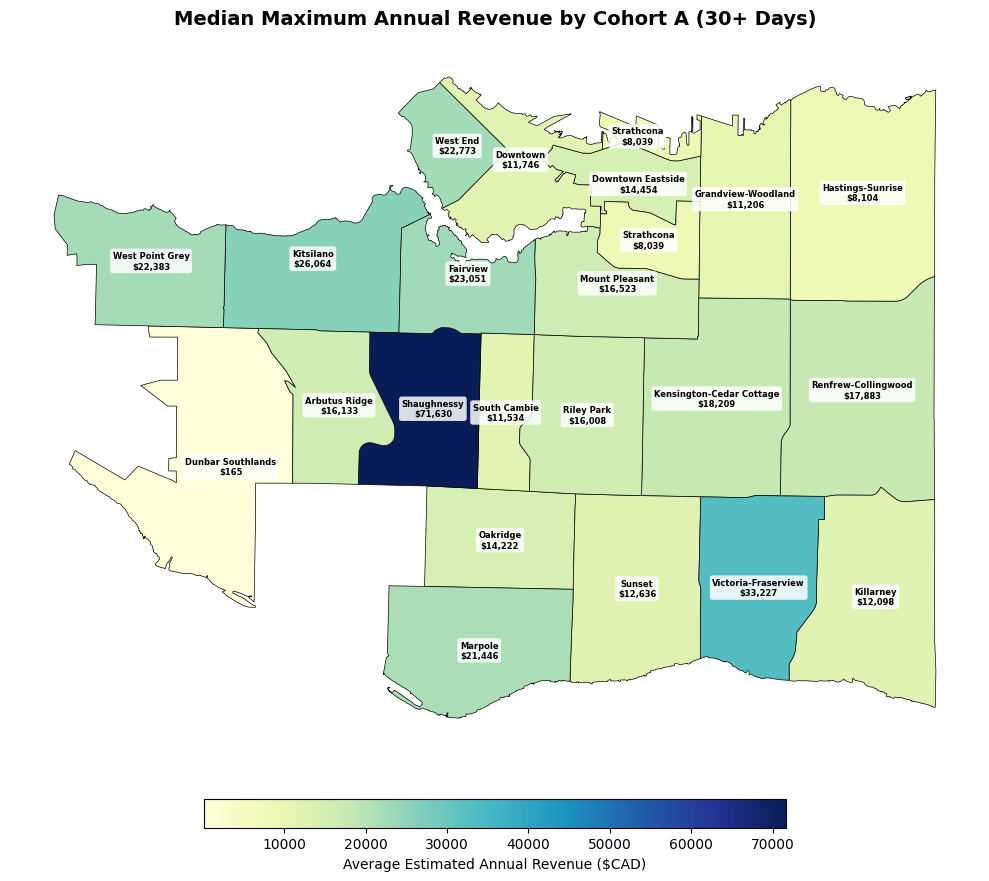

In [92]:
neighbourhood_revenue = df_mtr_merged.groupby('neighbourhood_cleansed', as_index=False).agg(avg_neighbourhood_revenue=("maximum_annual_revenue", "median"))
gdf_map = gdf_neighbourhoods.merge(
    neighbourhood_revenue,
    left_on="neighbourhood",
    right_on="neighbourhood_cleansed",
    how="left"
)

fig, ax = plt.subplots(1,1,figsize=(10,10))

gdf_map.plot(
    column='avg_neighbourhood_revenue',
    ax=ax,
    legend=True,
    cmap='YlGnBu',  # Color palette (Yellow-Green-Blue works well for financial data)
    edgecolor='black',
    linewidth=0.5,
    legend_kwds={
        'label': 'Average Estimated Annual Revenue ($CAD)',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'pad': 0.05
    }
)

for idx, row in gdf_map.iterrows():
    if pd.notna(row['avg_neighbourhood_revenue']):
        point = row['geometry'].representative_point()

        # Combine name on the first line and revenue amount on the second line
        label_text = f"{row['neighbourhood']}\n${row['avg_neighbourhood_revenue']:,.0f}"

        ax.text(
            point.x, point.y, label_text,
            fontsize=6,  # Compact font size to fit multi-line text cleanly
            ha='center',
            va='center',
            color='black',
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='none')
        )

plt.title('Median Maximum Annual Revenue by Cohort A (30+ Days)', fontsize=14, fontweight='bold', pad=15)
plt.axis('off')  # Hide latitude/longitude axes for a clean presentation look
plt.tight_layout()

# Save the figure so you can easily drop it straight into your pitch deck PowerPoint (.pptx)
plt.savefig('vancouver_revenue_map.png', dpi=300, bbox_inches='tight')
plt.show()

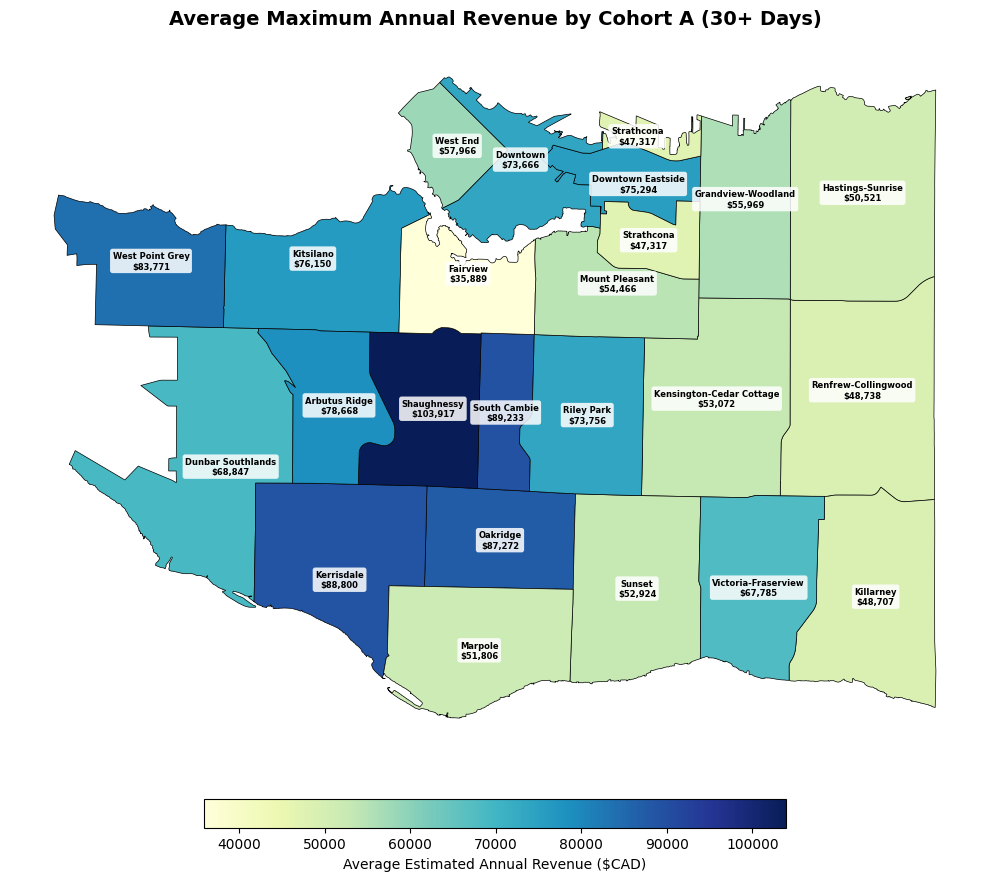

In [93]:
neighbourhood_revenue = df_active.groupby('neighbourhood_cleansed', as_index=False).agg(avg_neighbourhood_revenue=("maximum_annual_revenue", "mean"))
gdf_map = gdf_neighbourhoods.merge(
    neighbourhood_revenue,
    left_on="neighbourhood",
    right_on="neighbourhood_cleansed",
    how="left"
)

fig, ax = plt.subplots(1,1,figsize=(10,10))

gdf_map.plot(
    column='avg_neighbourhood_revenue',
    ax=ax,
    legend=True,
    cmap='YlGnBu',  # Color palette (Yellow-Green-Blue works well for financial data)
    edgecolor='black',
    linewidth=0.5,
    legend_kwds={
        'label': 'Average Estimated Annual Revenue ($CAD)',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'pad': 0.05
    }
)

for idx, row in gdf_map.iterrows():
    if pd.notna(row['avg_neighbourhood_revenue']):
        point = row['geometry'].representative_point()

        # Combine name on the first line and revenue amount on the second line
        label_text = f"{row['neighbourhood']}\n${row['avg_neighbourhood_revenue']:,.0f}"

        ax.text(
            point.x, point.y, label_text,
            fontsize=6,  # Compact font size to fit multi-line text cleanly
            ha='center',
            va='center',
            color='black',
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='none')
        )

plt.title('Average Maximum Annual Revenue by Cohort A (30+ Days)', fontsize=14, fontweight='bold', pad=15)
plt.axis('off')  # Hide latitude/longitude axes for a clean presentation look
plt.tight_layout()

# Save the figure so you can easily drop it straight into your pitch deck PowerPoint (.pptx)
plt.savefig('vancouver_revenue_map.png', dpi=300, bbox_inches='tight')
plt.show()

In [94]:
before_filter = df_listings.groupby('neighbourhood_cleansed', as_index=False).agg(neighbourhood_count=('neighbourhood_cleansed', 'count'))
after_filter = df_active.value_counts('neighbourhood_cleansed')
combined = before_filter.merge(after_filter, on='neighbourhood_cleansed', how='left')
combined.fillna(0, inplace=True)
#combined['neighbourhood_count_new'] = combined['neighbourhood_count_new'].astype(int)
#combined['neighbourhood_count'] = combined['neighbourhood_count'].astype(int)

print(combined)

      neighbourhood_cleansed  neighbourhood_count  count
0              Arbutus Ridge                  127     90
1                   Downtown                 1224   1068
2          Downtown Eastside                  326    299
3          Dunbar Southlands                  222    134
4                   Fairview                  100     86
5         Grandview-Woodland                  194    164
6           Hastings-Sunrise                  309    226
7   Kensington-Cedar Cottage                  327    251
8                 Kerrisdale                   88     52
9                  Killarney                  104     82
10                 Kitsilano                  327    278
11                   Marpole                  160    106
12            Mount Pleasant                  301    201
13                  Oakridge                   82     54
14       Renfrew-Collingwood                  237    192
15                Riley Park                  250    190
16               Shaughnessy   

In [166]:
def generate_df_demand(df=df_active, category_weights=[1/3, 1/3, 1/3]):
    df_transit = pd.read_csv("/content/rapid-transit-stations.csv", sep=";")
    df_bus_stops = pd.read_csv("/content/bus-stops.csv")
    df_census_full = pd.read_csv('/content/census.csv').T[[0,5]]

    neighbourhood_revenue = df.groupby('neighbourhood_cleansed', as_index=False).agg(median_neighbourhood_revenue=("maximum_annual_revenue", "median"))
    revenue = neighbourhood_revenue.rename(columns={'neighbourhood_cleansed': 'neighbourhood'})
    df_demand = df_census.merge(revenue, on='neighbourhood', how='left')
    df_demand.fillna(0, inplace=True)

    latitudes, longitudes = [], []
    for coords in df_transit['geo_point_2d']:
        latitudes.append(coords.split(', ')[0])
        longitudes.append(coords.split(', ')[1])

    df_transit['latitude'], df_transit['longitude'] = latitudes, longitudes
    df_transit = assign_23_neighbourhoods(df_transit)

    df_bus_stops = assign_23_neighbourhoods(df_bus_stops, 'stop_lat', 'stop_lon')

    transit_counts = df_bus_stops.groupby('neighbourhood', as_index=False).agg(bus_stop_count=('neighbourhood', 'count'))
    transit_counts = transit_counts.merge(df_transit.groupby('neighbourhood', as_index=False).agg(station_count=('neighbourhood', 'count')), on='neighbourhood', how='left')

    transit_counts.fillna(0, inplace=True)
    raw_transit = 2 * np.log(transit_counts['bus_stop_count']) + transit_counts['station_count']
    df_demand['transit_index'] = (raw_transit - raw_transit.min()) / (
        raw_transit.max() - raw_transit.min()
    )

    working_age = [
        int(df_census_full[5][i].replace(',','')) / int(df_census_full[0][i].replace(',',''))
        for i in range(2, 24)]

    # Accounting for DTES
    working_age = np.array(working_age[:2] + [0] + working_age[2:])
    working_age[2] = working_age[1] * sum(df_census['population'][[1, 2]])  # Downtown
    working_age[2] += working_age[18] * sum(df_census['population'][[2, 18]])  # Strathcona
    working_age[2] /= sum(df_census['population'][[1, 2, 2, 18]])

    df_demand['working_age'] = working_age

    df_demand['rentables_per_1000'] = df_active.value_counts('neighbourhood_cleansed').reset_index().sort_values(by='neighbourhood_cleansed').reset_index()['count']
    df_demand['rentables_per_1000'] *= 1000
    df_demand['rentables_per_1000'] /= df_demand['population']

    # 1. Select the raw demand features per neighborhood
    features = [
        'working_age',  # e.g., Census ages 20-64
        'rentables_per_1000',  # Amount of rentables per 1000 residents
        'transit_index',  # Inverse distance to SkyTrain / Downtown
    ]

    # 2. Min-Max normalize each column to [0, 1] so units don't skew the weights
    df_norm = df_demand[features].apply(
        lambda col: (col - col.min()) / (col.max() - col.min())
    )

    # 3. Apply transparent policy weights, relative to correlation indices (summing to 1.0)
    weights = {
        'working_age': category_weights[0],
        'rentables_per_1000': category_weights[1],
        'transit_index': category_weights[2],
    }

    df_demand['demand_index'] = sum(
        df_norm[col] * weight for col, weight in weights.items()
    )

    df_is = df_demand['median_neighbourhood_revenue'] * df_demand['demand_index']
    df_demand['investment_score'] = (df_is - df_is.min()) / (df_is.max() - df_is.min())

    return df_demand

In [179]:
generate_df_demand()

/tmp/ipykernel_6300/1606201526.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  int(df_census_full[5][i].replace(',','')) / int(df_census_full[0][i].replace(',',''))


,neighbourhood,population,median_neighbourhood_revenue,transit_index,working_age,rentables_per_1000,demand_index,investment_score
0,Arbutus Ridge,15295,71739.500,0.092504,0.641059,5.884276,0.135208,0.101617
1,Downtown,65785,63927.000,1.000000,0.826616,16.234704,1.000000,1.000000
2,Downtown Eastside,19700,68154.000,0.136797,0.790274,15.177665,0.623599,0.645032
3,Dunbar Southlands,21425,51890.000,0.134328,0.663477,6.254376,0.197608,0.110797
4,Fairview,34375,23188.735,0.251441,0.747769,2.501818,0.305057,0.058115
5,Grandview-Woodland,29570,46410.500,0.247127,0.772408,5.546162,0.415223,0.260180
6,Hastings-Sunrise,35345,42309.900,0.206919,0.692552,6.394115,0.277126,0.135173
7,Kensington-Cedar Cottage,51120,40748.000,0.325447,0.717385,4.910016,0.328415,0.162625
8,Kerrisdale,14320,65043.305,0.095617,0.672272,3.631285,0.142478,0.094452
9,Killarney,30235,44334.000,0.183957,0.681500,2.712089,0.168169,0.064439


/tmp/ipykernel_6300/1606201526.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  int(df_census_full[5][i].replace(',','')) / int(df_census_full[0][i].replace(',',''))


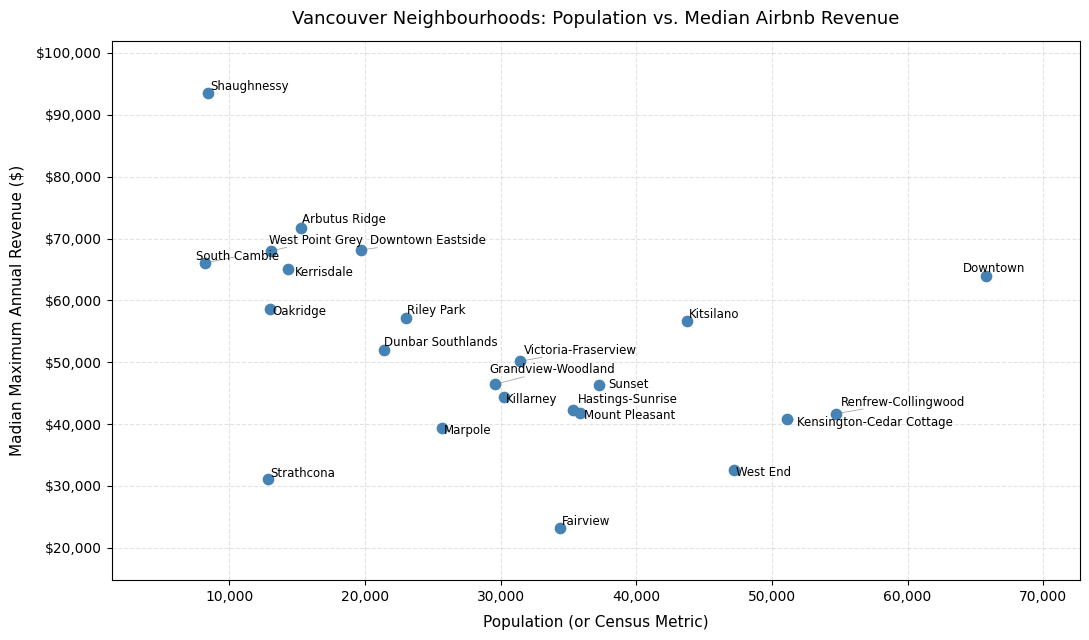

In [168]:
df_demand = generate_df_demand(df_active)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(
    df_demand['population'],
    df_demand['median_neighbourhood_revenue'],
    color='steelblue',
    s=55,
    zorder=3,
)

# Create text objects first (without xytext offset)
texts = [
    ax.text(x, y, label, fontsize=8.5)
    for x, y, label in zip(
        df_demand['population'],
        df_demand['median_neighbourhood_revenue'],
        df_demand['neighbourhood'],
    )
]

# Automatically repel overlapping labels and draw subtle pointer lines
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.6, alpha=0.7),
)

ax.margins(x=0.12, y=0.12)
ax.grid(True, linestyle='--', alpha=0.35, zorder=0)
ax.set_xlabel('Population (or Census Metric)', fontsize=11, labelpad=8)
ax.set_ylabel('Madian Maximum Annual Revenue ($)', fontsize=11, labelpad=8)
ax.set_title(
    'Vancouver Neighbourhoods: Population vs. Median Airbnb Revenue',
    fontsize=13,
    pad=12,
)

# Optional: Format tick numbers with commas and dollar signs
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

In [169]:
n = 23

m = n * sum(df_demand['population'] * df_demand['median_neighbourhood_revenue'])
m -= sum(df_demand['population']) * sum(df_demand['median_neighbourhood_revenue'])
m /= n * sum(df_demand['population'] ** 2) - sum(df_demand['population']) ** 2

b = sum(df_demand['median_neighbourhood_revenue']) - m * sum(df_demand['population'])
b /= n

print(m, b)

-0.4540568371856912 65458.24655793535


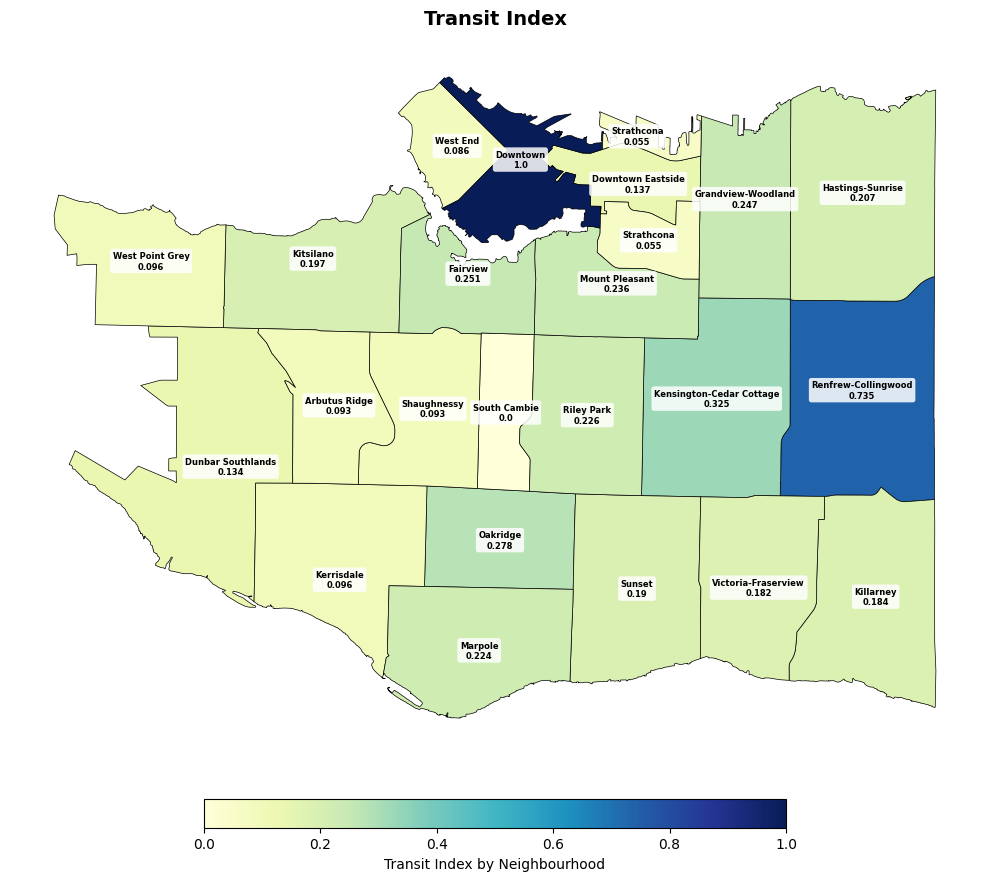

In [170]:
gdf_map = gdf_neighbourhoods.merge(
    df_demand,
    left_on="neighbourhood",
    right_on="neighbourhood",
    how="left"
)

fig, ax = plt.subplots(1,1,figsize=(10,10))

gdf_map.plot(
    column='transit_index',
    ax=ax,
    legend=True,
    cmap='YlGnBu',  # Color palette (Yellow-Green-Blue works well for financial data)
    edgecolor='black',
    linewidth=0.5,
    legend_kwds={
        'label': 'Transit Index by Neighbourhood',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'pad': 0.05
    }
)

for idx, row in gdf_map.iterrows():
    if pd.notna(row['transit_index']):
        point = row['geometry'].representative_point()

        # Combine name on the first line and revenue amount on the second line
        label_text = f"{row['neighbourhood']}\n{round(row['transit_index'], 3)}"

        ax.text(
            point.x, point.y, label_text,
            fontsize=6,  # Compact font size to fit multi-line text cleanly
            ha='center',
            va='center',
            color='black',
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='none')
        )

plt.title('Transit Index', fontsize=14, fontweight='bold', pad=15)
plt.axis('off')  # Hide latitude/longitude axes for a clean presentation look
plt.tight_layout()

# Save the figure so you can easily drop it straight into your pitch deck PowerPoint (.pptx)
plt.savefig('vancouver_transit_index_map.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_6300/1606201526.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  int(df_census_full[5][i].replace(',','')) / int(df_census_full[0][i].replace(',',''))


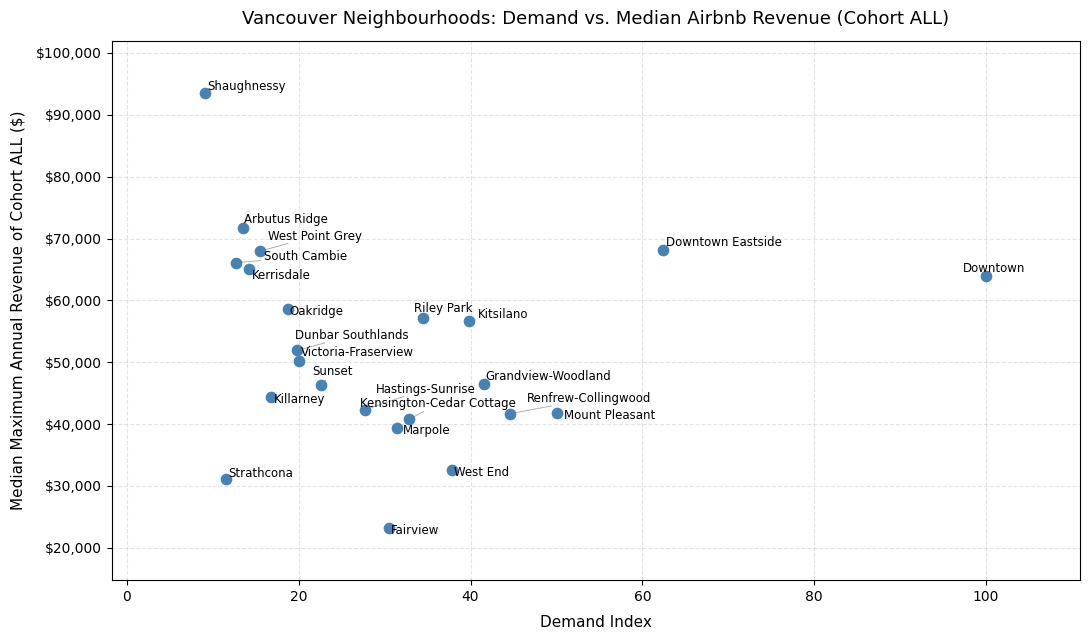

In [171]:
COHORT = 'ALL'
WEIGHTS = [
    1/3, # Working age population share
    1/3,  # Rentables per 1000 residents,
    1/3  # Transit Index
]


dfs = {'A': df_str, 'B': df_mtr, 'C': df_hybrid, 'D': df_flexible, 'ALL': df_active}

df_demand = generate_df_demand(df=dfs[COHORT], category_weights=WEIGHTS)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(
    df_demand['demand_index'] * 100,
    df_demand['median_neighbourhood_revenue'],
    color='steelblue',
    s=55,
    zorder=3,
)

texts = [
    ax.text(x, y, label, fontsize=8.5)
    for x, y, label in zip(
        df_demand['demand_index'] * 100,
        df_demand['median_neighbourhood_revenue'],
        df_demand['neighbourhood'],
    )
]

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.6, alpha=0.7),
)

ax.margins(x=0.12, y=0.12)
ax.grid(True, linestyle='--', alpha=0.35, zorder=0)
ax.set_xlabel('Demand Index', fontsize=11, labelpad=8)
ax.set_ylabel(f'Median Maximum Annual Revenue of Cohort {COHORT} ($)', fontsize=11, labelpad=8)
ax.set_title(
    f'Vancouver Neighbourhoods: Demand vs. Median Airbnb Revenue (Cohort {COHORT})',
    fontsize=13,
    pad=12,
)

ax.xaxis.set_major_formatter('{x:,.0f}')
ax.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

/tmp/ipykernel_6300/1606201526.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  int(df_census_full[5][i].replace(',','')) / int(df_census_full[0][i].replace(',',''))
/tmp/ipykernel_6300/1606201526.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  int(df_census_full[5][i].replace(',','')) / int(df_census_full[0][i].replace(',',''))
/tmp/ipykernel_6300/1606201526.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  int(df_censu

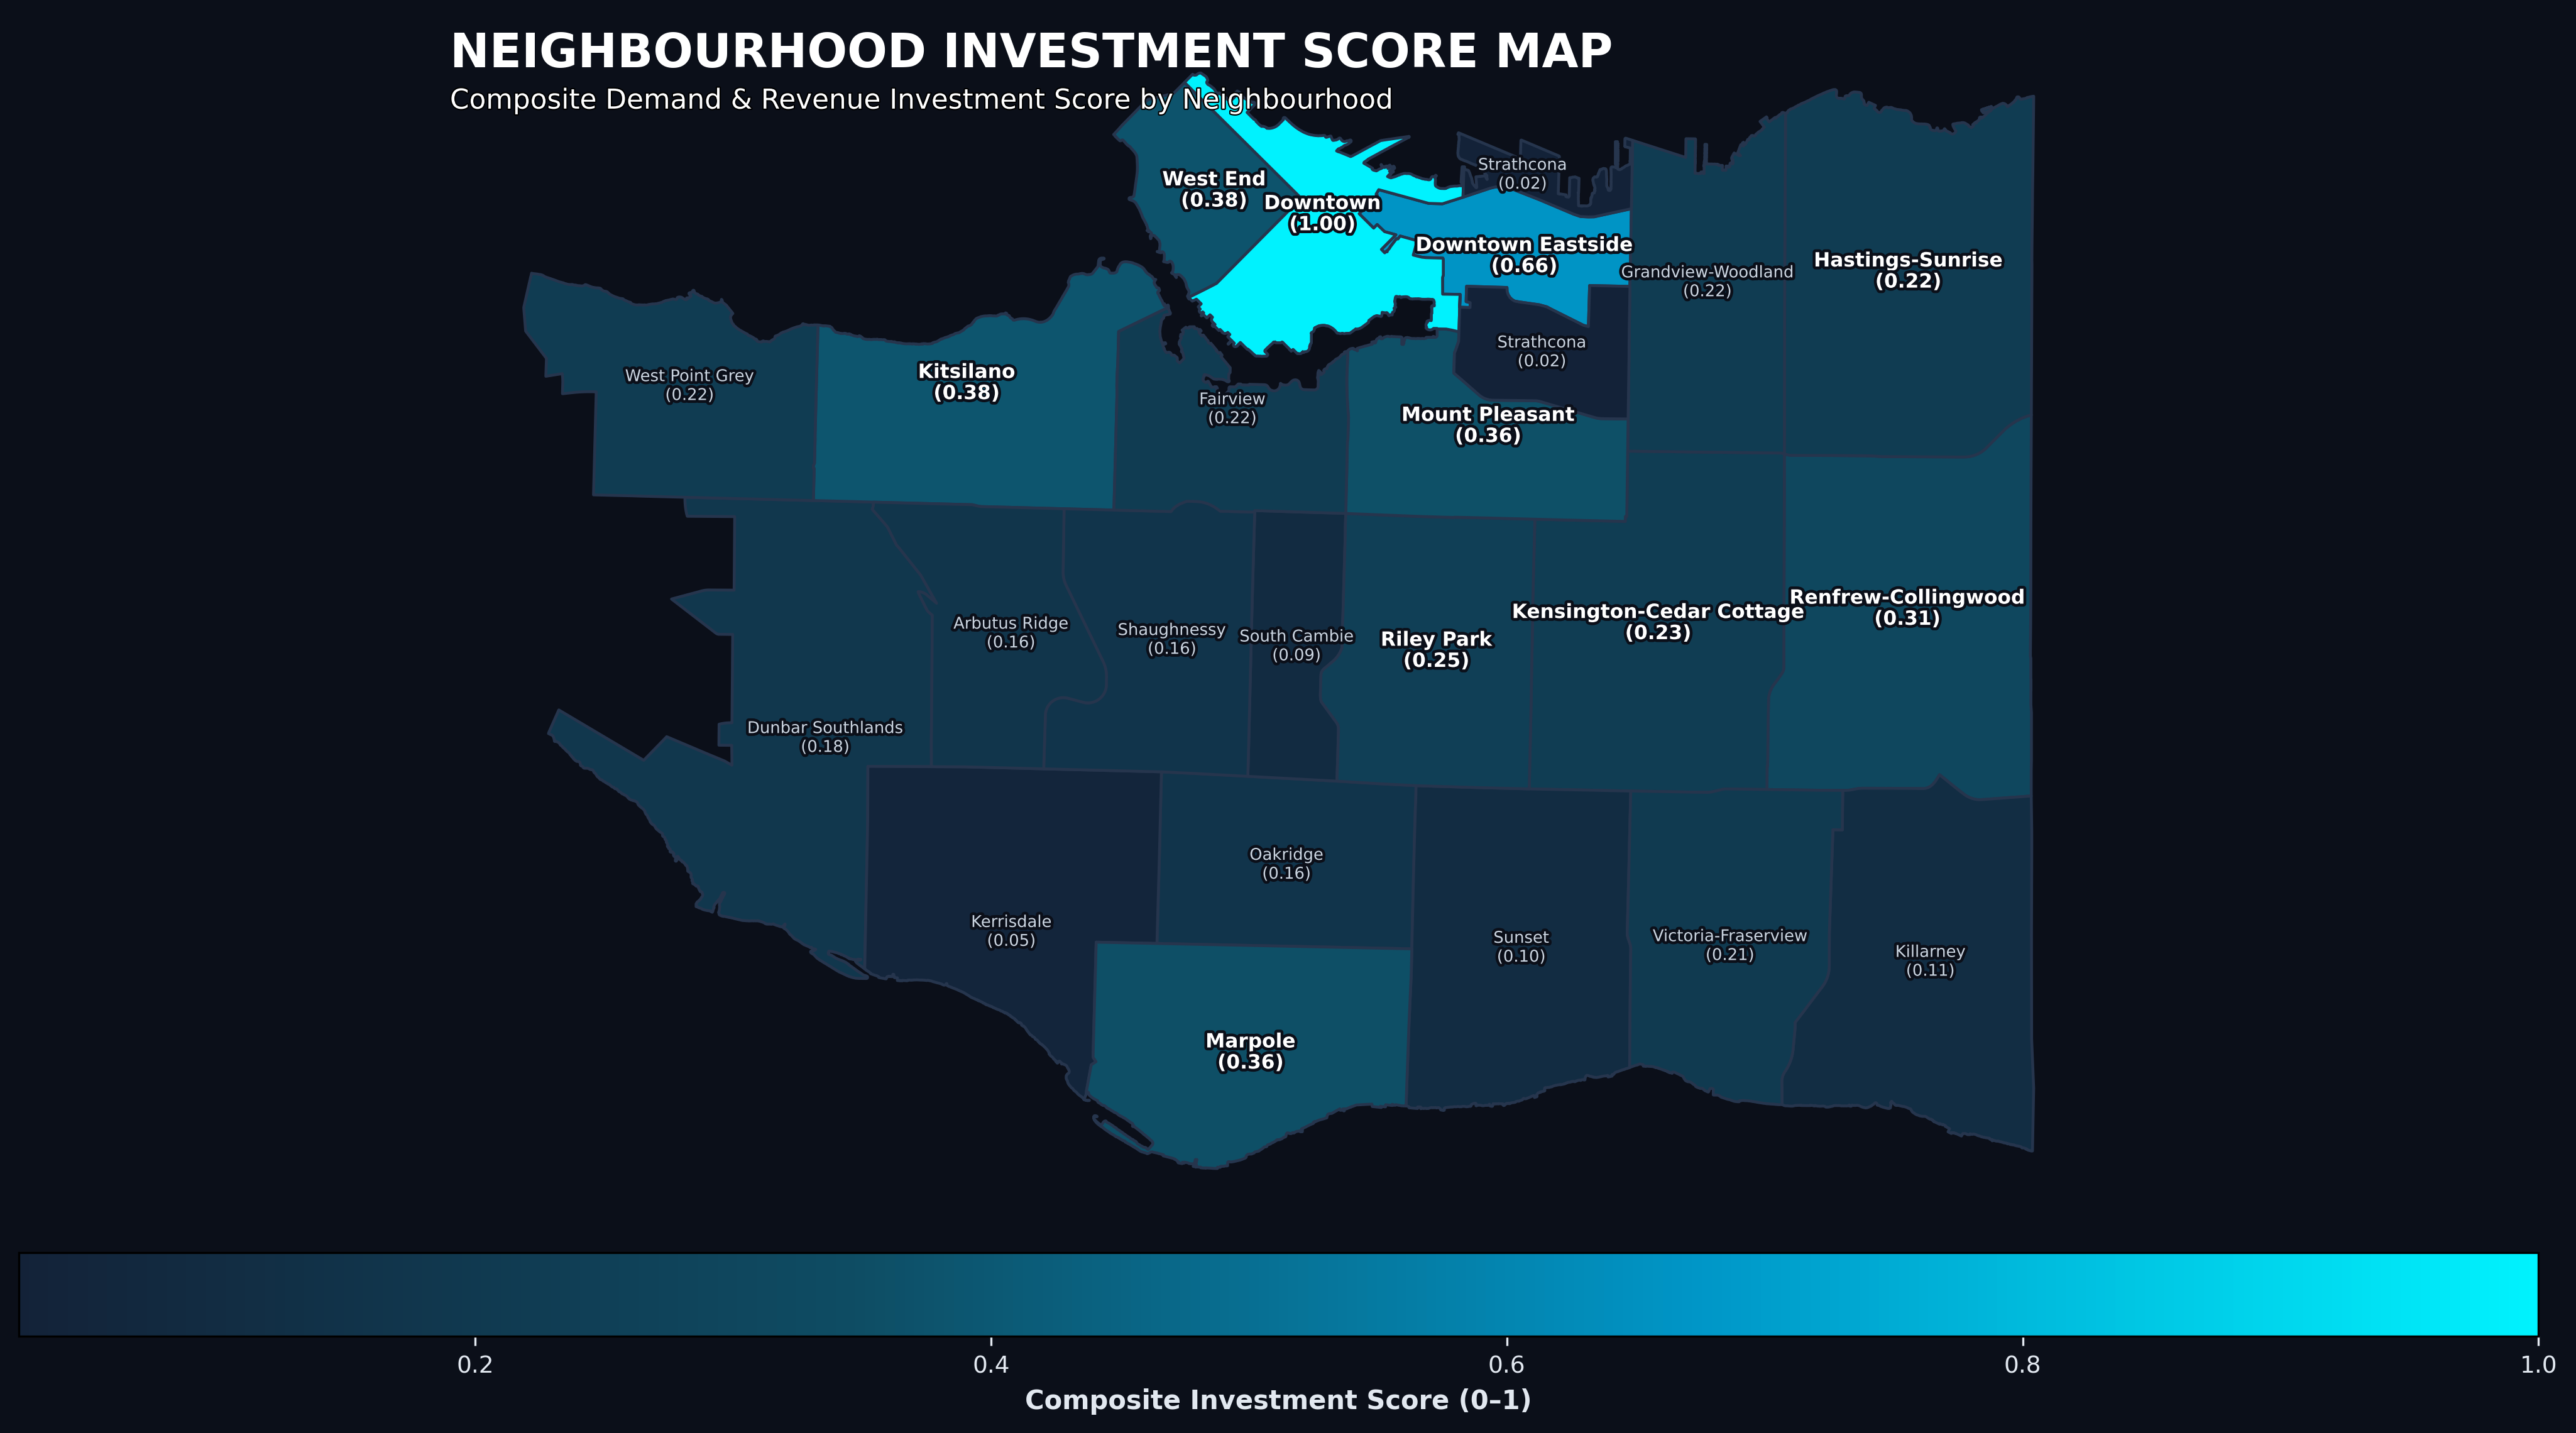

In [183]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.colors import LinearSegmentedColormap

# ==============================================================================
# 1. PREPARE DATA FROM df_demand
# ==============================================================================
# Use df_demand directly instead of recalculating from df_active
df_demand['investment_score'] = generate_df_demand(df_str, [0.1, 0.8, 0.1])['investment_score'] * 0.5
df_demand['investment_score'] += generate_df_demand(df_mtr, [0.5, 0.2, 0.3])['investment_score'] * 0.3
df_demand['investment_score'] += generate_df_demand(df_hybrid, [0.2, 0.2, 0.6])['investment_score'] * 0.2

scored_df = df_demand[['neighbourhood', 'investment_score']].copy()

# ==============================================================================
# 2. LOAD GEOJSON & MERGE SCORES
# ==============================================================================
gdf = gpd.read_file("neighbourhoods.geojson")

# InsideAirbnb GeoJSON files typically use 'neighbourhood' as the join column;
# fallback checks common alternatives if your file uses a different property name.
geo_col = next(
    (c for c in ['neighbourhood', 'neighbourhood_cleansed', 'name', 'NAME'] if c in gdf.columns),
    gdf.columns[0]
)

# Clean whitespace/case for reliable joining
gdf['join_key'] = gdf[geo_col].astype(str).str.strip().str.lower()
scored_df['join_key'] = scored_df['neighbourhood'].astype(str).str.strip().str.lower()

# Drop the 'neighbourhood' column from scored_df to avoid suffix conflicts (_x, _y) upon merging
scored_df_merge = scored_df.drop(columns=['neighbourhood'])
map_gdf = gdf.merge(scored_df_merge, on='join_key', how='left')

# Project to a local metric CRS (UTM Zone 10N for Vancouver) so centroids are accurate
map_gdf_proj = map_gdf.to_crs(epsg=32610)
map_gdf_proj['label_point'] = map_gdf_proj.geometry.representative_point()

# ==============================================================================
# 3. PLOT PRESENTATION CHOROPLETH MAP
# ==============================================================================
fig, ax = plt.subplots(figsize=(30, 8), dpi=300)
fig.patch.set_facecolor("#0B0F19")
ax.set_facecolor("#0B0F19")
ax.axis("off")

# Custom dark-teal to vibrant-cyan colormap matching your slide deck
cyan_cmap = LinearSegmentedColormap.from_list(
    "investor_cyan", ["#132238", "#0E4D64", "#0096C7", "#00F2FE"]
)

# Plot base layer
map_gdf_proj.plot(
    column="investment_score",
    cmap=cyan_cmap,
    linewidth=1.1,
    edgecolor="#26354D",
    ax=ax,
    legend=True,
    missing_kwds={
        "color": "#141B29",
        "edgecolor": "#26354D",
        "hatch": "//",
        "label": "No Data"
    },
    legend_kwds={
        "label": "Composite Investment Score (0–1)",
        "orientation": "horizontal",
        "shrink": 0.45,
        "pad": 0.02,
        "aspect": 30
    }
)

# Style the colorbar text for dark mode
cbar = ax.get_figure().axes[-1]
cbar.tick_params(colors="#E2E8F0", labelsize=9)
cbar.xaxis.label.set_color("#E2E8F0")
cbar.xaxis.label.set_fontsize(10)
cbar.xaxis.label.set_weight("bold")

# Identify top 10 threshold to highlight top performers
top_10_cutoff = scored_df['investment_score'].nlargest(10).min()

# Add Neighbourhood Name + Score Labels
for _, row in map_gdf_proj.iterrows():
    if pd.isna(row['investment_score']):
        continue

    pt = row['label_point']
    name = row[geo_col]
    score = row['investment_score']
    is_top_10 = score >= top_10_cutoff

    # Formatted to 2 decimal places for the 0-1 scale
    label_text = f"{name}\n({score:.2f})"

    txt = ax.text(
        pt.x, pt.y,
        label_text,
        fontsize=7.5 if is_top_10 else 6.2,
        fontweight="bold" if is_top_10 else "normal",
        color="#FFFFFF" if is_top_10 else "#CBD5E1",
        ha="center",
        va="center",
        zorder=5
    )
    # Add dark halo around text so labels remain legible over bright cyan polygons
    txt.set_path_effects([
        path_effects.Stroke(linewidth=2.2, foreground="#0B0F19"),
        path_effects.Normal()
    ])

# Title & Subtitle
plt.text(
    0.001, 0.96,
    "NEIGHBOURHOOD INVESTMENT SCORE MAP",
    fontsize=18, fontweight="bold", color="#FFFFFF", transform=ax.transAxes
)
plt.text(
    0.001, 0.925,
    "Composite Demand & Revenue Investment Score by Neighbourhood",
    fontsize=10.5, color="#FFFFFF", transform=ax.transAxes,
    path_effects=[path_effects.withStroke(linewidth=1, foreground="black")]
)

plt.tight_layout()
plt.savefig("neighbourhood_investment_map.png", dpi=300, bbox_inches="tight", facecolor="#0B0F19")
plt.show()